<a href="https://colab.research.google.com/github/abhisheksahoo6448/AtliQHardware_Sales_Analytics_Project/blob/main/Inflation_Dynamic_Factor_Modelling_Practise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('inflation_raw_data.csv')
df

,date,inflation(%),brent_crude_price($),fx_rate,money_supply(mn $),repo_rate
0,1/15/2021,4.06,54.77,73.109395,2523123.556,4.00
1,2/15/2021,5.03,62.28,72.756460,2541560.897,4.00
2,3/15/2021,5.52,65.41,72.792800,2563724.191,4.00
3,4/15/2021,4.23,64.81,74.472212,2555825.353,4.00
4,5/15/2021,6.30,68.53,73.267740,2621599.188,4.00
...,...,...,...,...,...,...
63,4/1/2026,3.48,117.29,93.550000,3272093.770,5.25
64,5/1/2026,3.93,107.14,95.597500,3287960.820,5.25
65,6/1/2026,4.38,85.40,94.969500,3371476.010,5.25
66,7/1/2026,4.45,83.76,95.821000,3384461.610,5.25


### Step 1: Data Preprocessing and Setting the Date Index
We will convert the `date` column into a `DatetimeIndex` and set a consistent monthly frequency to prepare the series for time-series modeling.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.dynamic_factor import DynamicFactor

# 1. Convert date to datetime
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df.set_index('date', inplace=True)

# Resample or set frequency to Monthly ('MS' or 'ME')
df = df.asfreq('MS', method='pad')

# Define variables
target = 'inflation(%)'
exog_cols = ['brent_crude_price($)', 'fx_rate', 'money_supply(mn $)', 'repo_rate']

print("Data prepared. Dimensions:", df.shape)
display(df.head())

Data prepared. Dimensions: (67, 5)


,inflation(%),brent_crude_price($),fx_rate,money_supply(mn $),repo_rate
date,,,,,
2021-02-01,4.06,54.77,73.109395,2523123.556,4.0
2021-03-01,5.03,62.28,72.756460,2541560.897,4.0
2021-04-01,5.52,65.41,72.792800,2563724.191,4.0
2021-05-01,4.23,64.81,74.472212,2555825.353,4.0
2021-06-01,6.30,68.53,73.267740,2621599.188,4.0


### Step 1.1: Stationarity Diagnostics (ADF Test)
We will run the Augmented Dickey-Fuller (ADF) test on each variable to verify if it is stationary. If the p-value is greater than 0.05, the series is non-stationary and needs to be differenced.

In [ ]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series, name):
    result = adfuller(series.dropna())
    p_value = result[1]
    is_stationary = p_value < 0.05
    print(f"{name:<25} | ADF Statistic: {result[0]:.4f} | p-value: {p_value:.4f} | Stationary? {is_stationary}")
    return is_stationary

print("=== Stationarity Test on Raw Data ===")
stationarity_results = {}
all_cols = [target] + exog_cols
for col in all_cols:
    stationarity_results[col] = check_stationarity(df[col], col)

=== Stationarity Test on Raw Data ===
inflation(%)              | ADF Statistic: -1.5708 | p-value: 0.4982 | Stationary? False
brent_crude_price($)      | ADF Statistic: -2.9753 | p-value: 0.0373 | Stationary? True
fx_rate                   | ADF Statistic: 0.5731 | p-value: 0.9869 | Stationary? False
money_supply(mn $)        | ADF Statistic: 0.3175 | p-value: 0.9781 | Stationary? False
repo_rate                 | ADF Statistic: -2.2472 | p-value: 0.1896 | Stationary? False


/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag ar

### Step 1.2: Differencing Non-Stationary Variables
We will take the first difference for variables that are non-stationary. We'll store the original last values so we can revert the differencing transformation after forecasting.

In [ ]:
# We will create a differenced dataframe
df_diff = df.copy()
differenced_cols = []

for col in all_cols:
    if not stationarity_results[col]:
        df_diff[col] = df[col].diff()
        differenced_cols.append(col)

# Drop the first row which now contains NaN due to differencing
df_diff.dropna(inplace=True)

print("\n=== Stationarity Test after First-Differencing ===")
for col in all_cols:
    check_stationarity(df_diff[col], col)

print("\nDifferenced columns:", differenced_cols)


=== Stationarity Test after First-Differencing ===
inflation(%)              | ADF Statistic: -3.2242 | p-value: 0.0186 | Stationary? True
brent_crude_price($)      | ADF Statistic: -2.8403 | p-value: 0.0528 | Stationary? False
fx_rate                   | ADF Statistic: -8.5348 | p-value: 0.0000 | Stationary? True
money_supply(mn $)        | ADF Statistic: -8.9550 | p-value: 0.0000 | Stationary? True
repo_rate                 | ADF Statistic: -2.3303 | p-value: 0.1624 | Stationary? False

Differenced columns: ['inflation(%)', 'fx_rate', 'money_supply(mn $)', 'repo_rate']


/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
/tmp/ipykernel_603/1251122393.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag ar

### Step 2 (Updated): Fit VAR and Forecast Exogenous Variables in Differenced Space

In [ ]:
# Fit VAR on differenced exogenous data
var_data_diff = df_diff[exog_cols].copy()
var_model = VAR(var_data_diff)
selected_lag = var_model.select_order(maxlags=5).selected_orders['aic']

var_results = var_model.fit(selected_lag)
var_forecast_diff = var_results.forecast(var_data_diff.values[-selected_lag:], steps=forecast_steps)

# Create DataFrame for forecasted differenced values
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=forecast_steps, freq='MS')
df_exog_forecast_diff = pd.DataFrame(var_forecast_diff, index=future_dates, columns=exog_cols)

# Revert differencing to get forecasted exogenous variables on their original scale
df_exog_forecast_undiff = df_exog_forecast_diff.copy()
for col in exog_cols:
    if col in differenced_cols:
        # Cumulative sum of differenced forecasts added to the last known historical value
        df_exog_forecast_undiff[col] = df[col].iloc[-1] + df_exog_forecast_diff[col].cumsum()

print("Forecasted Exogenous Variables (Undifferenced / Original Scale):")
display(df_exog_forecast_undiff.head())

Forecasted Exogenous Variables (Undifferenced / Original Scale):


,brent_crude_price($),fx_rate,money_supply(mn $),repo_rate
2026-09-01,95.158973,95.548734,3.453184e+06,5.244289
2026-10-01,94.939681,96.364350,3.476759e+06,5.310585
2026-11-01,95.898873,96.415084,3.473123e+06,5.361050
2026-12-01,90.873695,96.923097,3.488275e+06,5.492199
2027-01-01,91.207833,97.206782,3.500518e+06,5.578483


### Step 3 (Updated): Fit Dynamic Factor Model on Differenced Data and Invert Forecast

In [ ]:
# Combine target and exogenous differenced variables for joint dynamic factor modeling
dfm_data_diff = df_diff[[target] + exog_cols].copy()

# Fit DFM on stationary differenced data
model_dfm = DynamicFactor(dfm_data_diff, k_factors=3, factor_order=3)
results_dfm = model_dfm.fit(disp=False)

# Forecast the system forward
dfm_forecast_diff = results_dfm.get_forecast(steps=forecast_steps)
forecast_mean_diff = dfm_forecast_diff.predicted_mean
confidence_intervals_diff = dfm_forecast_diff.conf_int()

# Revert the target forecasting back to original scale
if target in differenced_cols:
    forecast_mean_inflation = df[target].iloc[-1] + forecast_mean_diff[target].cumsum()

    # Correctly retrieve forecast standard errors
    forecast_se_diff = dfm_forecast_diff.se_mean[target]
    cumulative_se = np.sqrt(np.cumsum(forecast_se_diff**2))

    lower_ci_inflation = forecast_mean_inflation - 1.96 * cumulative_se
    upper_ci_inflation = forecast_mean_inflation + 1.96 * cumulative_se
else:
    forecast_mean_inflation = forecast_mean_diff[target]
    lower_ci_inflation = confidence_intervals_diff[f'lower {target}']
    upper_ci_inflation = confidence_intervals_diff[f'upper {target}']

# Combine back into a clean forecast DataFrame
forecast_df_stationary = pd.DataFrame({
    'Forecasted_Inflation(%)': forecast_mean_inflation,
    'Lower_CI': lower_ci_inflation,
    'Upper_CI': upper_ci_inflation
}, index=future_dates)

display(forecast_df_stationary)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Forecasted_Inflation(%),Lower_CI,Upper_CI
2026-09-01,5.068855,2.354639,7.783070
2026-10-01,5.138488,1.185069,9.091907
2026-11-01,5.216074,0.299615,10.132533
2026-12-01,5.285110,-0.495911,11.066131
2027-01-01,5.352559,-1.185494,11.890611
2027-02-01,5.444313,-1.780776,12.669402
2027-03-01,5.502636,-2.360653,13.365924
2027-04-01,5.556800,-2.898031,14.011632
2027-05-01,5.624322,-3.386016,14.634660
2027-06-01,5.680326,-3.855996,15.216648


### Step 4 (Updated): Plot Stationary DFM Forecast

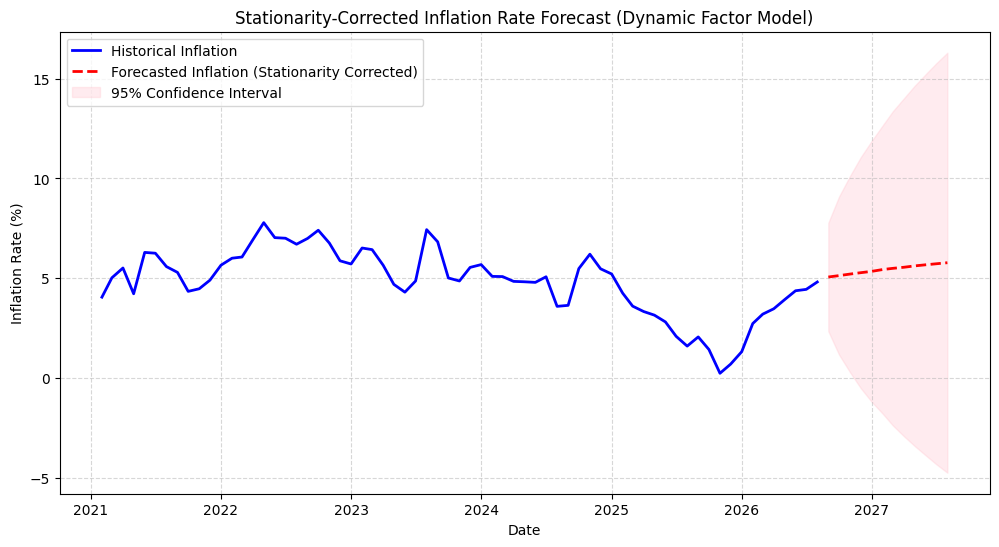

In [ ]:
# Plot historical vs stationarity-adjusted forecast
plt.figure(figsize=(12, 6))
plt.plot(df.index, df[target], label='Historical Inflation', color='blue', linewidth=2)
plt.plot(forecast_df_stationary.index, forecast_df_stationary['Forecasted_Inflation(%)'], label='Forecasted Inflation (Stationarity Corrected)', color='red', linestyle='--', linewidth=2)
plt.fill_between(forecast_df_stationary.index, forecast_df_stationary['Lower_CI'], forecast_df_stationary['Upper_CI'], color='pink', alpha=0.3, label='95% Confidence Interval')

plt.title('Stationarity-Corrected Inflation Rate Forecast (Dynamic Factor Model)')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Step 2: Forecasting Exogenous Variables
To project our target variable into the future, we need the future values of our exogenous variables. We can use a **Vector Autoregression (VAR)** model to capture the joint dynamics of these exogenous variables and forecast them forward.

In [ ]:
# Let's forecast the exogenous variables 12 months into the future
forecast_steps = 12

# Fit a VAR model on the exogenous variables
var_data = df[exog_cols].copy()
var_model = VAR(var_data)

# Select best lag order automatically
lag_order = var_model.select_order(maxlags=5)
selected_lag = lag_order.selected_orders['aic']
print(f"Selected lag order for VAR: {selected_lag}")

var_results = var_model.fit(selected_lag)

# Forecast exogenous variables
var_forecast = var_results.forecast(var_data.values[-selected_lag:], steps=forecast_steps)

# Create a DataFrame for the forecasted exogenous values
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=forecast_steps, freq='MS')
df_exog_forecast = pd.DataFrame(var_forecast, index=future_dates, columns=exog_cols)

print("Forecasted Exogenous Variables (Future):")
display(df_exog_forecast.head())

Selected lag order for VAR: 3
Forecasted Exogenous Variables (Future):


,brent_crude_price($),fx_rate,money_supply(mn $),repo_rate
2026-09-01,101.759975,97.054998,3.484657e+06,5.181438
2026-10-01,100.649683,97.999056,3.526204e+06,5.146579
2026-11-01,98.365746,98.797089,3.560401e+06,5.206869
2026-12-01,99.902840,99.804041,3.586816e+06,5.262978
2027-01-01,102.992115,101.140824,3.611262e+06,5.299171


### Step 3: Fit Dynamic Factor Model & Forecast Inflation
Now, we will train a Dynamic Factor Model (or state-space representation) using both our target variable (Inflation) and our exogenous features, then use the forecasted exogenous variables to project future Inflation.

In [ ]:
from statsmodels.tsa.statespace.dynamic_factor import DynamicFactor

# Combine target and exogenous variables into a single dataset for joint dynamic factor modeling
dfm_data = df[[target] + exog_cols].copy()

# Define Dynamic Factor Model
# k_factors: number of unobserved common factors (we will use 1 for simplicity)
# factor_order: lag order of the factor transition equation (AR(1))
model = DynamicFactor(dfm_data, k_factors=1, factor_order=1)
results = model.fit(disp=False)

# Forecast the system forward by 12 steps
dfm_forecast = results.get_forecast(steps=forecast_steps)
forecast_mean_all = dfm_forecast.predicted_mean
confidence_intervals_all = dfm_forecast.conf_int()

# Extract forecasted inflation and its confidence intervals
forecast_mean_inflation = forecast_mean_all[target]
lower_ci_inflation = confidence_intervals_all[f'lower {target}']
upper_ci_inflation = confidence_intervals_all[f'upper {target}']

# Combine results for visualization
forecast_df = pd.DataFrame({
    'Forecasted_Inflation(%)': forecast_mean_inflation,
    'Lower_CI': lower_ci_inflation,
    'Upper_CI': upper_ci_inflation
}, index=future_dates)

display(forecast_df)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Forecasted_Inflation(%),Lower_CI,Upper_CI
2026-09-01,5.344204,-2.331826,13.020235
2026-10-01,5.205918,-4.888523,15.300358
2026-11-01,5.071210,-6.873609,17.016028
2026-12-01,4.939987,-8.527620,18.407594
2027-01-01,4.812160,-9.955962,19.580282
2027-02-01,4.687641,-11.216530,20.591811
2027-03-01,4.566343,-12.345423,21.478110
2027-04-01,4.448185,-13.367090,22.263459
2027-05-01,4.333083,-14.299077,22.965244
2027-06-01,4.220961,-15.154537,23.596458


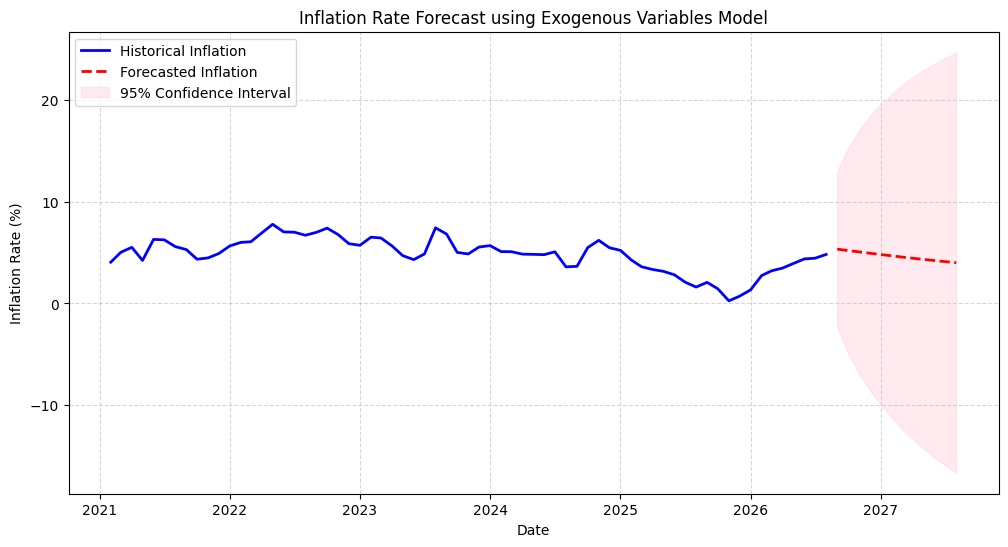

In [ ]:
# Plot the historical and forecasted Inflation rate
plt.figure(figsize=(12, 6))
plt.plot(df.index, df[target], label='Historical Inflation', color='blue', linewidth=2)
plt.plot(forecast_df.index, forecast_df['Forecasted_Inflation(%)'], label='Forecasted Inflation', color='red', linestyle='--', linewidth=2)
plt.fill_between(forecast_df.index, forecast_df['Lower_CI'], forecast_df['Upper_CI'], color='pink', alpha=0.3, label='95% Confidence Interval')

plt.title('Inflation Rate Forecast using Exogenous Variables Model')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()